In [233]:
%load_ext autoreload
%autoreload 2

import numpy as np 
import functions 

from matplotlib import pyplot as plt
from scipy.optimize import least_squares
from random import randint
from itertools import product

import importlib
import functions
import scattering_model

importlib.reload(functions)
importlib.reload(scattering_model)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<module 'scattering_model' from '/Users/peytaguo/Desktop/ASC/Nucelar Resonance Analysis /scattering_model.py'>

In [3]:
ne_amu = 19.9869544
a_amu = 4.001506179129

mg_amu = 23.9784588
uc2 = 931.494 #MeV

energy_threshold = (ne_amu + a_amu - mg_amu)*uc2
print(energy_threshold)

9.316597247987401


In [75]:
sigma = np.load("data/peyta_sigma1.npy")
dsigma = np.load("data/peyta_dsigma1.npy")
theta_cm = np.load("data/peyta_theta_cm1.npy")
ke_cm = np.load("data/peyta_ke_cm1.npy")

rounded_theta_cm = np.round(theta_cm, 1)
rounded_theta_cm[rounded_theta_cm == 53.2] = 53.1
rounded_theta_cm[rounded_theta_cm == 143.2] = 143.1
rounded_theta_cm[rounded_theta_cm == 155.7] = 155.8

print( np.unique( rounded_theta_cm ) )
print(len(np.unique(rounded_theta_cm)))

[ 53.1  58.8  70.   75.5  86.2  91.4 101.6 106.5 116.2 125.5 130.  138.8
 143.1 155.8 163.9 168. ]
16


In [76]:
all_cs = functions.get_all_cs(rounded_theta_cm, ke_cm, sigma, dsigma, 9.31)
#functions.visualise_all_peaks(all_cs)

In [78]:
clusters_dp_chosen = functions.get_clusters_dp(all_cs, 0.001, 0.005)

In [86]:
clusters_dp_chosen[0]

[np.float64(13.32186782827972),
 [[58.8, np.float64(13.315620272331726), np.float64(0.48017776796147543)],
  [53.1, np.float64(13.328115384227713), np.float64(0.696244297387564)]]]

In [94]:
cluster_widths = functions.get_cluster_widths(clusters_dp_chosen)

In [ ]:
#functions.get_dp_clusters_info(clusters_dp_chosen)

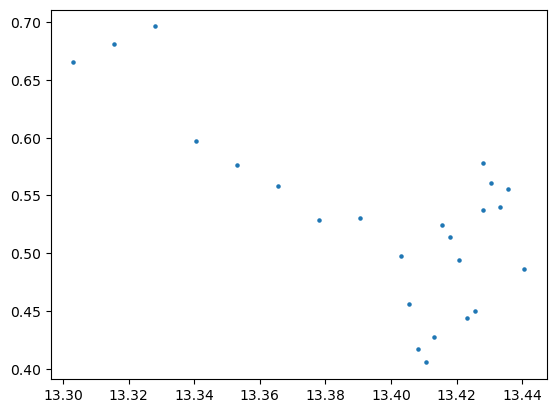

In [252]:
angles = list(all_cs.keys())

#all_cs[angles[0]].keys() -> 'ke', 'sigma', 'dsigma'

sigma_531 = all_cs[angles[0]]['sigma']
ke_531 = all_cs[angles[0]]['ke']

E_min, E_max = 13, 13.45

mask = (ke_531 >= E_min) & (ke_531 <= E_max)

E_window = ke_531[mask]
sigma_window = sigma_531[mask]

plt.scatter(
    E_window, 
    sigma_window,
    s=5
)
plt.show()

In [251]:
cluster_energies = [cluster[0] for cluster in clusters_dp_chosen]
cluster_widths = functions.get_cluster_widths(clusters_dp_chosen)

initial_parameters = scattering_model.get_initial_parameters(
    cluster_energies,
    cluster_widths,
    E_min,
    E_max
)

print(cluster_energies)

[np.float64(13.32186782827972), np.float64(13.379647365167385), np.float64(13.420724960967716), np.float64(13.478503549358422), np.float64(13.554854287229828), np.float64(13.636278844758236), np.float64(13.68791759034153), np.float64(13.731515116522399), np.float64(13.779079089074513), np.float64(13.824890878203005), np.float64(13.863283520137786), np.float64(13.908262928283293), np.float64(14.02283366705244), np.float64(14.059876681221004), np.float64(14.095513128862724), np.float64(14.144741357771649), np.float64(14.170529678049867), np.float64(14.255868680681997), np.float64(14.331302842044678), np.float64(14.390549114451925), np.float64(14.463505344036344), np.float64(14.497741458028996), np.float64(14.548318080561536), np.float64(14.62324668213953), np.float64(14.6578396757273), np.float64(14.69437965149989), np.float64(14.757488310032965), np.float64(14.84187951342079), np.float64(14.88494707406901), np.float64(14.924782404250218), np.float64(14.99110263791823), np.float64(15.064

In [253]:
window = scattering_model.get_window_cs(all_cs, E_min, E_max)

number_of_resonances = int((len(initial_parameters) - 32)/5)

angular_momenta = [randint(0,5) for _ in range(number_of_resonances)]

intial_parameters = scattering_model.get_initial_parameters(
    cluster_energies,
    cluster_widths,
    E_min,
    E_max
)

lower_bound, upper_bound = scattering_model.get_bounds(E_min, E_max, cluster_energies)

initial_res = scattering_model.get_residual(intial_parameters, angular_momenta, window)

#print(initial_res)

In [254]:
print("Initial parameters:", np.shape(intial_parameters))
print("Lower bounds:", np.shape(lower_bound))
print("Upper bounds:", np.shape(upper_bound))

Initial parameters: (47,)
Lower bounds: (47,)
Upper bounds: (47,)


In [ ]:
fits = []

combinations = list(product(range(6), repeat=number_of_resonances))
total = len(combinations)

for i, angular_momenta in enumerate(combinations, start=1):
    fit = least_squares(
    scattering_model.get_residual,
    x0 = intial_parameters,
    args = (angular_momenta, window),
    bounds = (lower_bound, upper_bound),
    max_nfev = 200,
    verbose = 1
)
    fits.append((fit, angular_momenta))

    print(
    f"\rProgress: {100*i/total:.1f}% "
    f"({i}/{total})",
    end="",
    flush=True
    )
    
fits.sort(key=lambda fit: fit[0].cost)
top_fits = fits[:10]



The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 5.3156e+08, final cost 1.6129e-03, first-order optimality 2.11e-03.
Progress: 0.5% (1/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.9462e+08, final cost 1.3469e-03, first-order optimality 2.93e-04.
Progress: 0.9% (2/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 5.2585e+08, final cost 7.7156e-05, first-order optimality 4.50e-04.
Progress: 1.4% (3/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 5.5382e+08, final cost 4.8934e-04, first-order optimality 5.87e-04.
Progress: 1.9% (4/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.7384e+08, final cost 5.0280e-04, first-order optimality 1.95e-04.
Progress: 2.3% (5/216)The maximum number of function evaluations is exceeded.
Function evaluation

In [277]:
import pickle

with open("top_10_fits.pkl", "wb") as f:
    pickle.dump(top_fits, f)

In [278]:
refined_fits = []

for i, (fit, angular_momenta) in enumerate(top_fits, start=1):

    fit = least_squares(
        scattering_model.get_residual,
        x0=fit.x,
        args=(angular_momenta, window),
        bounds=(lower_bound, upper_bound),
        max_nfev=3000,
        verbose=1
    )

    refined_fits.append(
        (fit.cost, angular_momenta, fit.x)
    )

    print(f"\r {100*i/len(top_fits):.1f}% complete",
          end="", flush=True)

# Rank by refined cost
refined_fits.sort(key=lambda fit: fit[0])

`xtol` termination condition is satisfied.
Function evaluations 115, initial cost 1.0908e-05, final cost 1.0273e-05, first-order optimality 6.82e-08.
 10.0% complete`xtol` termination condition is satisfied.
Function evaluations 43, initial cost 3.1836e-05, final cost 2.1240e-05, first-order optimality 5.90e-07.
 20.0% complete`xtol` termination condition is satisfied.
Function evaluations 151, initial cost 3.8438e-05, final cost 3.8024e-05, first-order optimality 2.41e-07.
 30.0% complete`xtol` termination condition is satisfied.
Function evaluations 352, initial cost 4.0926e-05, final cost 2.3977e-05, first-order optimality 1.68e-06.
 40.0% complete`xtol` termination condition is satisfied.
Function evaluations 516, initial cost 4.3621e-05, final cost 3.0184e-05, first-order optimality 5.02e-07.
 50.0% complete`xtol` termination condition is satisfied.
Function evaluations 115, initial cost 4.4908e-05, final cost 3.6823e-05, first-order optimality 2.20e-07.
 60.0% complete`ftol` term

In [282]:
# Save all 10 refined results
with open("top_10_refined_fits.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

In [283]:
best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

In [284]:
print(best_angular_momenta)
print(best_params)

(1, 3, 4)
[ 1.33796925e+01  1.23429836e-01  2.35903584e-01  3.10377639e-01
  2.20488699e+00  1.34258834e+01  1.93587076e-02  1.00881615e-01
 -5.95532075e-01  5.44772237e+00  1.34133383e+01  9.13824259e-03
  5.36658984e-02  6.75604049e-01  1.45965303e+00 -6.52282606e-01
  8.01975154e+00 -6.82230790e-02  3.61635970e-01  4.23409416e-01
 -6.03061271e+00  5.74879647e-01 -8.03346899e+00  2.32477407e-01
 -3.43853998e+00  1.23409901e-01 -1.95869828e+00  6.09096709e-02
 -6.10256775e-01  2.72894930e-01 -3.49204795e+00  2.08350183e+00
 -2.78723431e+01  2.65705793e+00 -3.55269452e+01  3.35574310e+00
 -4.48579424e+01  1.56495903e+00 -2.09774042e+01  2.40463626e+00
 -3.22428310e+01  6.04134397e+00 -8.04869182e+01  7.39929350e+00
 -9.86202524e+01  7.23560331e+00 -9.63495081e+01]


Resonance 1: E_r = 13.379693 MeV, l = 1, Gamma = 0.123430 MeV
Resonance 2: E_r = 13.425883 MeV, l = 3, Gamma = 0.019359 MeV
Resonance 3: E_r = 13.413338 MeV, l = 4, Gamma = 0.009138 MeV


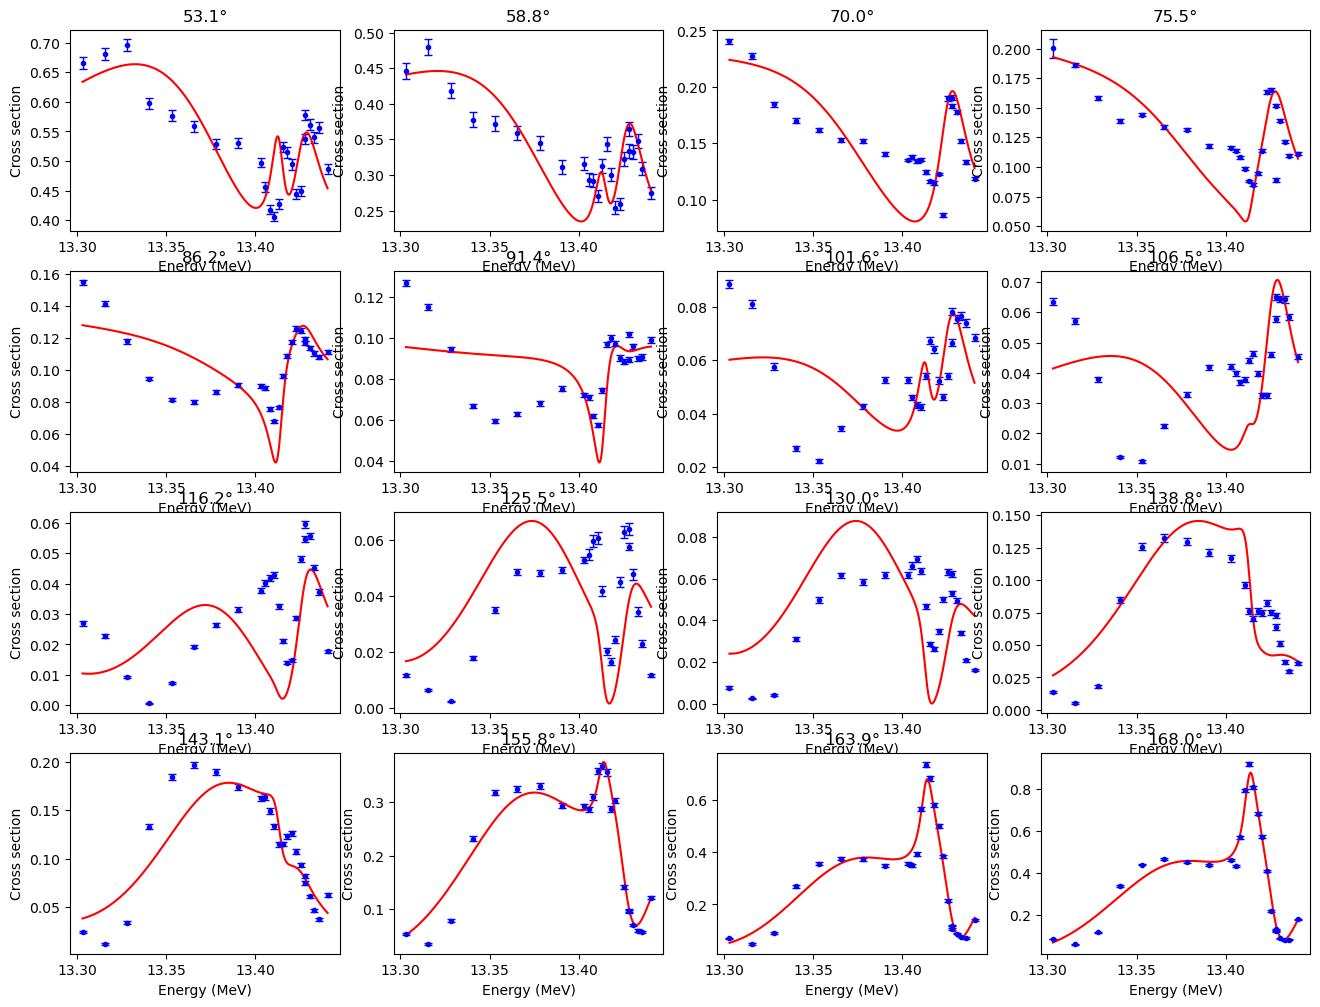

(1, 3, 4)


In [311]:
scattering_model.get_fit_visual(window, best_params, best_angular_momenta)
print(best_angular_momenta)

In [302]:
clusters = scattering_model.get_window_clusters(cluster_energies)

In [304]:
windows = scattering_model.get_windows(all_cs, clusters)

In [305]:
print(windows)

[{'53.1': {'ke': array([13.30312496, 13.31562058, 13.3281162 , 13.3406118 , 13.3531074 ]), 'sigma': array([0.6657981 , 0.6814729 , 0.69624526, 0.59739744, 0.57650716]), 'dsigma': array([0.01001236, 0.01014121, 0.01026775, 0.00940706, 0.00921349]), 'E_min': array([13.28186783]), 'E_max': array([13.36186783])}, '58.8': {'ke': array([13.30312496, 13.31562058, 13.3281162 , 13.3406118 , 13.3531074 ]), 'sigma': array([0.44632314, 0.48017861, 0.41842769, 0.37780415, 0.37211629]), 'dsigma': array([0.01130235, 0.01111344, 0.01092501, 0.01035562, 0.01027388]), 'E_min': array([13.28186783]), 'E_max': array([13.36186783])}, '70.0': {'ke': array([13.30312496, 13.31562058, 13.3281162 , 13.3406118 , 13.3531074 ]), 'sigma': array([0.24017163, 0.22727568, 0.1843991 , 0.17003576, 0.16210812]), 'dsigma': array([0.00232712, 0.00224088, 0.00199628, 0.00185014, 0.00179007]), 'E_min': array([13.28186783]), 'E_max': array([13.36186783])}, '75.5': {'ke': array([13.30312496, 13.31562058, 13.3281162 , 13.3406118

/var/folders/64/560xbkqj7xxf0gnjkybhj9mr0000gn/T/ipykernel_1852/3301661300.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


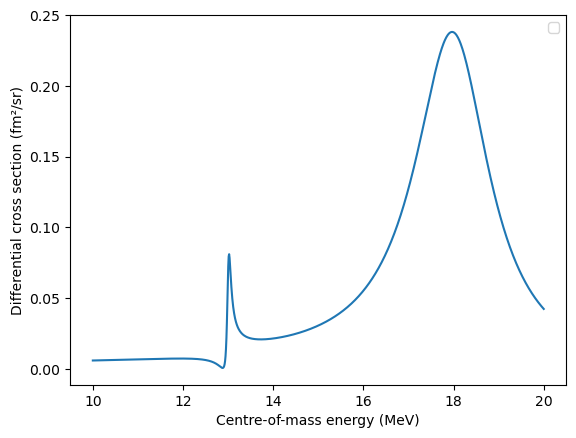

In [36]:
#testing

resonances = [
    {
        "angular m" : 2,
        "p width ratio" : 0.3,
        "width": 0.1,
        "r energy": 13,
        "a": 0.0,
        "b": 0.0
    },
    {
            "angular m" : 5,
            "p width ratio" : 0.2,
            "width": 2,
            "r energy": 18,
            "a": 0.0,
            "b": 0.0
        }
]

energy = np.linspace(10, 20, 1000)
theta = np.deg2rad(45)

sigma = scattering_model.model(
    theta,
    energy,
    resonances,
    m=0,
    c=0
)

import matplotlib.pyplot as plt

plt.plot(energy, sigma)

plt.xlabel("Centre-of-mass energy (MeV)")
plt.ylabel("Differential cross section (fm²/sr)")
plt.legend()
plt.show()

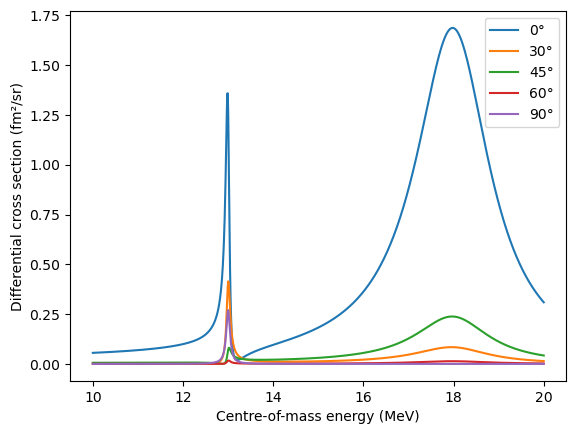

In [37]:
for angle in [0, 30, 45, 60, 90]:
    sigma = scattering_model.model(
        np.deg2rad(angle),
        energy,
        resonances,
        m=0,
        c=0
    )

    plt.plot(energy, sigma, label=f"{angle}°")

plt.xlabel("Centre-of-mass energy (MeV)")
plt.ylabel("Differential cross section (fm²/sr)")
plt.legend()
plt.show()